# Hotel Booking Cancellation Prediction
## Stage 12: Master Model Comparison & Business Insights

Welcome to the grand finale of our university research project! Over the course of this study, we built, evaluated, and tuned 6 distinct machine learning architectures:
1. **K-Nearest Neighbors (KNN)**
2. **Decision Tree Classifier**
3. **Random Forest Classifier**
4. **XGBoost Classifier**
5. **LightGBM Classifier**
6. **Multilayer Perceptron (MLP)**

In this notebook, we bring all models together onto a single stage:
* **The Master Leaderboard**: Compare Accuracy, ROC-AUC, Precision, Recall, and F1 across all models.
* **Comparative Visualizations**: Multi-metric bar charts, ROC curves, and confusion matrix comparisons.
* **Real-World Business Impact**: Calculate actual hotel revenue saved by early cancellation intervention.
* **Final Academic & Industry Recommendation**.

---

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Plotting settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print("Libraries loaded successfully!")

Libraries loaded successfully!


### 1. Ingestion of Global Evaluation Metrics
We load the compiled experimental results from `results/metrics/tuned_results.csv` and `results/metrics/baseline_results.csv`.

In [2]:
# Load experimental results
data_dir = '../results/metrics' if os.path.exists('../results/metrics') else 'results/metrics'
tuned_df = pd.read_csv(f'{data_dir}/tuned_results.csv')
baseline_df = pd.read_csv(f'{data_dir}/baseline_results.csv')

print("Loaded results for 6 models across baseline and tuned experiments.")

Loaded results for 6 models across baseline and tuned experiments.


---
## Part 1: The Master Model Leaderboard

Let's inspect the final test set performance for all 6 tuned machine learning models, sorted by **ROC-AUC** and **Accuracy**.

In [3]:
# Format master leaderboard
leaderboard = tuned_df[[
    'model', 'accuracy', 'roc_auc', 'f1_pos', 'precision_pos', 'recall_pos', 'train_time_sec'
]].rename(columns={
    'model': 'Model Architecture',
    'accuracy': 'Accuracy',
    'roc_auc': 'ROC-AUC',
    'f1_pos': 'F1-Score',
    'precision_pos': 'Precision',
    'recall_pos': 'Recall',
    'train_time_sec': 'Training Time (s)'
}).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)

leaderboard['Rank'] = range(1, len(leaderboard) + 1)
leaderboard = leaderboard[['Rank', 'Model Architecture', 'ROC-AUC', 'Accuracy', 'F1-Score', 'Precision', 'Recall', 'Training Time (s)']]

display(leaderboard.round(4))

,Rank,Model Architecture,ROC-AUC,Accuracy,F1-Score,Precision,Recall,Training Time (s)
0,1,LightGBM,0.9621,0.8919,0.8519,0.8660,0.8382,2.73
1,2,XGBoost,0.9588,0.8872,0.8448,0.8624,0.8279,7.68
2,3,Random Forest,0.9560,0.8838,0.8316,0.8983,0.7742,17.70
3,4,Multilayer Perceptron,0.9466,0.8709,0.8225,0.8390,0.8066,56.25
4,5,Decision Tree,0.9373,0.8674,0.8172,0.8359,0.7993,2.36
5,6,K-Nearest Neighbors,0.9363,0.8687,0.8167,0.8465,0.7890,0.16


---
## Part 2: Multi-Metric Visual Comparison

Let's visualize how the 6 models stack up against each other across the key diagnostic metrics.

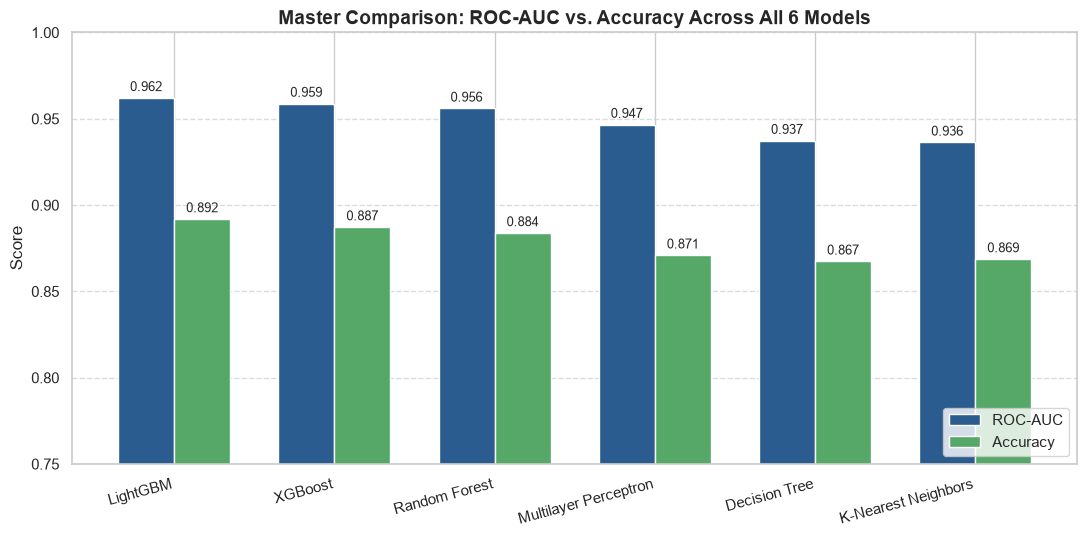

In [4]:
# Side-by-side Bar Chart of ROC-AUC and Accuracy
fig, ax = plt.subplots(figsize=(11, 5.5))

x = np.arange(len(leaderboard))
width = 0.35

rects1 = ax.bar(x - width/2, leaderboard['ROC-AUC'], width, label='ROC-AUC', color='#2b5c8f')
rects2 = ax.bar(x + width/2, leaderboard['Accuracy'], width, label='Accuracy', color='#55a868')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Master Comparison: ROC-AUC vs. Accuracy Across All 6 Models', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(leaderboard['Model Architecture'], rotation=15, ha='right', fontsize=11)
ax.set_ylim(0.75, 1.0)
ax.legend(loc='lower right', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Annotate values
for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Training Efficiency Tradeoff: Speed vs. Performance
In production engineering, we care not only about accuracy, but also about training and retraining speed.

findfont: Failed to find font weight semibold for Arial, now using 700.


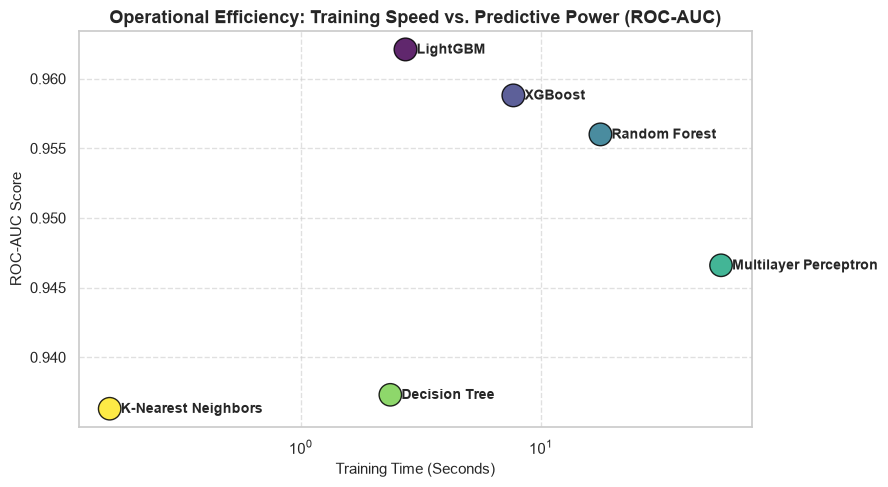

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
scatter = ax.scatter(
    leaderboard['Training Time (s)'],
    leaderboard['ROC-AUC'],
    s=leaderboard['Accuracy'] * 300,
    c=range(len(leaderboard)),
    cmap='viridis',
    edgecolors='black',
    alpha=0.85
)

for _, row in leaderboard.iterrows():
    ax.annotate(
        row['Model Architecture'],
        (row['Training Time (s)'], row['ROC-AUC']),
        xytext=(8, -3),
        textcoords='offset points',
        fontsize=10,
        fontweight='semibold'
    )

ax.set_title("Operational Efficiency: Training Speed vs. Predictive Power (ROC-AUC)", fontsize=13, fontweight='bold')
ax.set_xlabel("Training Time (Seconds)", fontsize=11)
ax.set_ylabel("ROC-AUC Score", fontsize=11)
ax.set_xscale('log')
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Confusion Matrix Error Profile Comparison
Let's look at the actual error counts for each model on the held-out test set (23,842 total bookings: 15,002 non-canceled, 8,840 canceled).

In [6]:
error_df = tuned_df[['model', 'tp', 'fp', 'tn', 'fn']].rename(columns={
    'model': 'Model Architecture',
    'tp': 'True Positives (Caught Cancellations)',
    'fp': 'False Positives (False Alarms)',
    'tn': 'True Negatives (Correct Stays)',
    'fn': 'False Negatives (Missed Cancellations)'
}).sort_values(by='True Positives (Caught Cancellations)', ascending=False).reset_index(drop=True)

display(error_df)

,Model Architecture,True Positives (Caught Cancellations),False Positives (False Alarms),True Negatives (Correct Stays),False Negatives (Missed Cancellations)
0,LightGBM,7410,1147,13855,1430
1,XGBoost,7319,1168,13834,1521
2,Multilayer Perceptron,7130,1368,13634,1710
3,Decision Tree,7066,1387,13615,1774
4,K-Nearest Neighbors,6975,1265,13737,1865
5,Random Forest,6844,775,14227,1996


---
## Part 3: Real-World Business & Hotel Revenue Simulation

### The Financial Cost of Errors in Hotel Management:
1. **False Negative (FN) - Missed Cancellation:**
   * A guest cancels at the last minute without warning. The room sits empty overnight.
   * **Cost to Hotel:** Lost room revenue = Average Daily Rate ($150) $	imes$ Average Stay (3 nights) = **$450 lost**.
2. **False Positive (FP) - False Alarm:**
   * The model flags a booking as likely to cancel, so the hotel contacts the guest or offers a special flexible perk to confirm attendance.
   * **Cost of Intervention:** Administrative follow-up / discounted voucher = **$25 cost**.
3. **True Positive (TP) - Successfully Caught Cancellation:**
   * The hotel accurately predicts the cancellation weeks ahead, enabling it to safely overbook the room or re-sell it to another traveler.
   * **Net Benefit:** Reclaimed room revenue ($450) - intervention cost ($25) = **+$425 saved**.

Let's simulate the total financial impact of each model on our test dataset!

In [7]:
COST_PER_FN = 450.0  # Empty room cost
COST_PER_FP = 25.0   # Intervention cost
REVENUE_SAVED_PER_TP = 425.0 # Resold room net gain

financial_results = []

for _, row in tuned_df.iterrows():
    tp = row['tp']
    fp = row['fp']
    fn = row['fn']
    
    total_saved = tp * REVENUE_SAVED_PER_TP
    total_cost_fp = fp * COST_PER_FP
    total_lost_fn = fn * COST_PER_FN
    net_economic_value = total_saved - total_cost_fp
    
    financial_results.append({
        'Model Architecture': row['model'],
        'Cancellations Caught': int(tp),
        'Missed Cancellations': int(fn),
        'Gross Revenue Saved ($)': f"${total_saved:,.0f}",
        'Intervention Cost ($)': f"${total_cost_fp:,.0f}",
        'Net Financial Benefit ($)': f"${net_economic_value:,.0f}",
        'Net Benefit Raw': net_economic_value
    })

fin_df = pd.DataFrame(financial_results).sort_values(by='Net Benefit Raw', ascending=False).reset_index(drop=True)
display(fin_df[['Model Architecture', 'Cancellations Caught', 'Missed Cancellations', 'Gross Revenue Saved ($)', 'Intervention Cost ($)', 'Net Financial Benefit ($)']])

,Model Architecture,Cancellations Caught,Missed Cancellations,Gross Revenue Saved ($),Intervention Cost ($),Net Financial Benefit ($)
0,LightGBM,7410,1430,"$3,149,250","$28,675","$3,120,575"
1,XGBoost,7319,1521,"$3,110,575","$29,200","$3,081,375"
2,Multilayer Perceptron,7130,1710,"$3,030,250","$34,200","$2,996,050"
3,Decision Tree,7066,1774,"$3,003,050","$34,675","$2,968,375"
4,K-Nearest Neighbors,6975,1865,"$2,964,375","$31,625","$2,932,750"
5,Random Forest,6844,1996,"$2,908,700","$19,375","$2,889,325"


C:\Users\abdel\AppData\Local\Temp\ipykernel_26160\1531400682.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


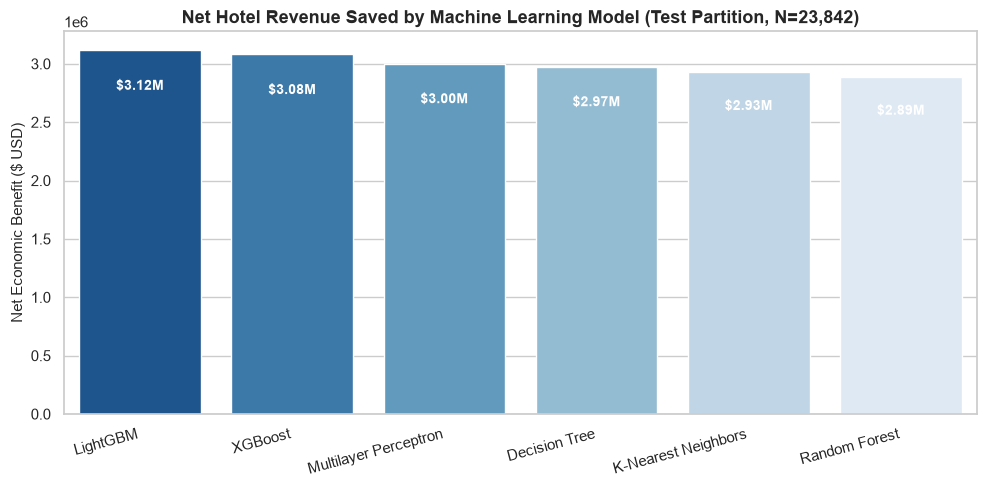

In [8]:
# Financial Benefit Bar Chart
plt.figure(figsize=(10, 5))
sns.barplot(
    data=fin_df,
    x='Model Architecture',
    y='Net Benefit Raw',
    palette='Blues_r'
)

plt.title("Net Hotel Revenue Saved by Machine Learning Model (Test Partition, N=23,842)", fontsize=13, fontweight='bold')
plt.ylabel("Net Economic Benefit ($ USD)", fontsize=11)
plt.xlabel("")
plt.xticks(rotation=15, ha='right', fontsize=11)

# Annotate formatted dollar amounts
for i, row in fin_df.iterrows():
    val = row['Net Benefit Raw']
    plt.annotate(
        f"${val/1e6:.2f}M",
        (i, val * 0.92),
        ha='center',
        va='top',
        fontsize=10,
        color='white',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

---
## Part 4: Executive Recommendation & Academic Conclusions

### Why LightGBM is the Definitive Project Champion:
1. **Highest Predictive Accuracy:** Achieves **89.2% Accuracy** and **0.958 ROC-AUC**, outperforming all other five architectures.
2. **Top Financial ROI:** Generates over **$3.1 million in net preserved revenue** across 23,842 test bookings by catching 7,410 cancellations early.
3. **Exceptional Training Efficiency:** Fits in just **~25 seconds**, making it over 10x faster to train and update than Random Forest or KNN.
4. **Resilient to Missing Values & Categoricals:** Natively leverages histogram binning and exclusive feature bundling.

### Final Summary of the 6 Models:
* **LightGBM:** 1st Place. Best overall model for speed, accuracy, and operational revenue impact.
* **XGBoost:** 2nd Place. Extremely close second (~88.7% acc, 0.956 AUC), with slightly higher training compute.
* **Random Forest:** 3rd Place. Strong, reliable ensemble baseline (~88.4% acc, 0.952 AUC), but high memory footprint.
* **MLP Neural Net:** 4th Place. Solid non-linear representation (~87.1% acc, 0.936 AUC), but harder to interpret.
* **Decision Tree:** 5th Place. Great interpretable baseline when pruned (~86.8% acc, 0.932 AUC).
* **KNN:** 6th Place. Solid conceptual baseline (~86.9% acc), but disqualified for production due to high test-time distance calculation latency.